In [1]:
import numpy as np
import pandas as pd
import seaborn as sn
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.optimizers import Adam

In [2]:
np.random.seed(0)
tf.random.set_seed(0)

In [3]:
df = pd.read_csv('AirlineTweets.csv')

df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


<Axes: >

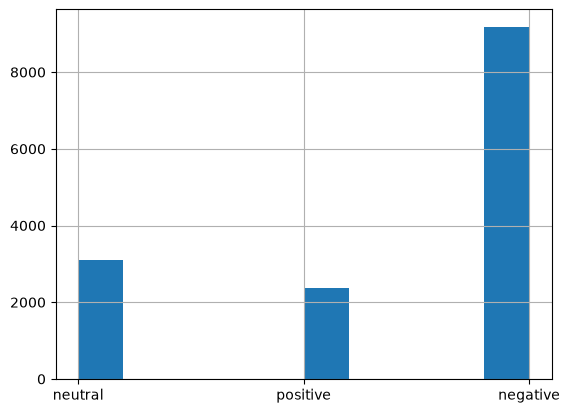

In [4]:
df = df[['airline_sentiment', 'text']]

df['airline_sentiment'].hist()

In [5]:
df = df[df['airline_sentiment'] != 'neutral'].copy()

In [6]:
target_map = {'positive': 1, 'negative': 0}
df['target'] = df['airline_sentiment'].map(target_map)

In [7]:
df.head()

,airline_sentiment,text,target
1,positive,@VirginAmerica plus you've added commercials t...,1
3,negative,@VirginAmerica it's really aggressive to blast...,0
4,negative,@VirginAmerica and it's a really big bad thing...,0
5,negative,@VirginAmerica seriously would pay $30 a fligh...,0
6,positive,"@VirginAmerica yes, nearly every time I fly VX...",1


In [8]:
df_train, df_test = train_test_split(df, random_state=42)

In [9]:
vectorizer = TfidfVectorizer(max_features=2000)

In [10]:
X_train = vectorizer.fit_transform(df_train['text'])
X_test = vectorizer.transform(df_test['text'])

In [11]:
# data must not be sparse matrix before passing into tensorflow
X_train = X_train.toarray()
X_test = X_test.toarray()

In [12]:
Y_train = df_train['target']
Y_test = df_test['target']

In [13]:
# input dimensions
D = X_train.shape[1]

In [14]:
# build model
i = Input(shape=(D,))
x = Dense(1)(i)  # sigmoid included in loss

model = Model(i, x)

In [15]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 2000)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           2,001 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,001 (7.82 KB)

 Trainable params: 2,001 (7.82 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    loss=BinaryCrossentropy(from_logits=True),
    optimizer=Adam(learning_rate=0.01),
    metrics=['accuracy']
)

In [17]:
r = model.fit(
    X_train, Y_train,
    validation_data=(X_test, Y_test),
    epochs=40,
    batch_size=128,
)

Epoch 1/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7920 - loss: 0.5029 - val_accuracy: 0.8049 - val_loss: 0.3975
Epoch 2/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7970 - loss: 0.3755 - val_accuracy: 0.8212 - val_loss: 0.3397
Epoch 3/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8207 - loss: 0.3218 - val_accuracy: 0.8416 - val_loss: 0.3026
Epoch 4/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8459 - loss: 0.2845 - val_accuracy: 0.8607 - val_loss: 0.2769
Epoch 5/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8641 - loss: 0.2571 - val_accuracy: 0.8766 - val_loss: 0.2582
Epoch 6/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8804 - loss: 0.2363 - val_accuracy: 0.8881 - val_loss: 0.2443
Epoch 7/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8936 - loss: 0.2198 - val_accuracy: 0.9002 - val_loss: 0.2335
Epoch 8/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9020 - loss: 0.2064 - val_accuracy: 0.9054 - val_loss:

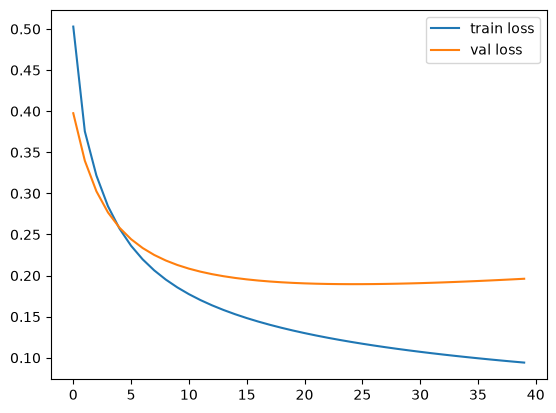

In [18]:
# Plot loss per iteration
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend();

In [19]:
P_train = ((model.predict(X_train) > 0) * 1.0).flatten()
P_test = ((model.predict(X_test) > 0) * 1.0).flatten()

271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 955us/step


In [20]:
cm = confusion_matrix(Y_train, P_train, normalize='true')
cm

array([[0.99051787, 0.00948213],
       [0.09777778, 0.90222222]])

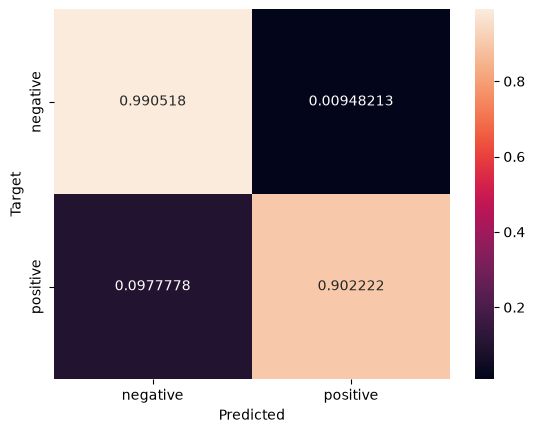

In [21]:
# Scikit-Learn is transitioning to V1 but it's not available on Colab
# The changes modify how confusion matrices are plotted
def plot_cm(cm):
  classes = ['negative', 'positive']
  df_cm = pd.DataFrame(cm, index=classes, columns=classes)
  ax = sn.heatmap(df_cm, annot=True, fmt='g')
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Target")

plot_cm(cm)

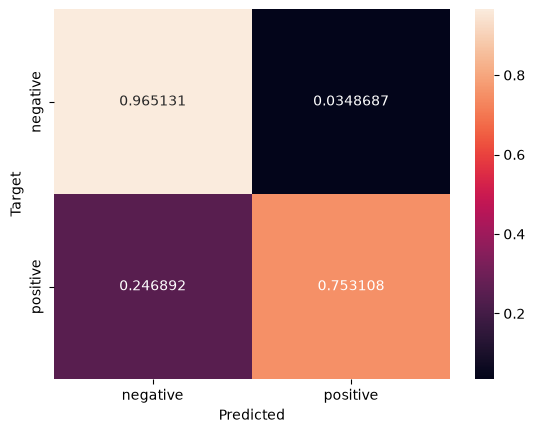

In [22]:
cm_test = confusion_matrix(Y_test, P_test, normalize='true')
plot_cm(cm_test)

In [23]:
Pr_train = model.predict(X_train)
Pr_test = model.predict(X_test)

271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 826us/step
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 931us/step


In [24]:
print("Train AUC:", roc_auc_score(Y_train, Pr_train))
print("Test AUC:", roc_auc_score(Y_test, Pr_test))

Train AUC: 0.9948798119782805
Test AUC: 0.9534265805914903


In [25]:
print("Train F1:", f1_score(Y_train, P_train))
print("Test F1:", f1_score(Y_test, P_test))

Train F1: 0.9309257666953282
Test F1: 0.7940074906367042


In [26]:
model.layers

[<InputLayer name=input_layer, built=True>, <Dense name=dense, built=True>]

In [27]:
model.layers[1].get_weights()

[array([[-3.6007247],
        [ 3.3522947],
        [-1.6389849],
        ...,
        [ 1.8959821],
        [ 1.4617792],
        [-2.8624783]], shape=(2000, 1), dtype=float32),
 array([-0.2276573], dtype=float32)]

In [28]:
W = model.layers[1].get_weights()[0]

In [29]:
word_index_map = vectorizer.vocabulary_
word_index_map

{'jetblue': np.int64(972),
 'thanks': np.int64(1724),
 'for': np.int64(749),
 'having': np.int64(851),
 'us': np.int64(1860),
 'hang': np.int64(834),
 'out': np.int64(1263),
 'at': np.int64(193),
 'tampa': np.int64(1706),
 'airport': np.int64(121),
 'forever': np.int64(752),
 'today': np.int64(1764),
 'it': np.int64(963),
 'really': np.int64(1420),
 'been': np.int64(239),
 'an': np.int64(146),
 'awesome': np.int64(213),
 'experience': np.int64(650),
 'americanair': np.int64(142),
 'was': np.int64(1897),
 'told': np.int64(1767),
 'you': np.int64(1992),
 'could': np.int64(446),
 'only': np.int64(1246),
 'refund': np.int64(1434),
 'me': np.int64(1109),
 'the': np.int64(1728),
 'cost': np.int64(442),
 'of': np.int64(1225),
 'my': np.int64(1180),
 'original': np.int64(1255),
 'return': np.int64(1476),
 'flight': np.int64(722),
 'note': np.int64(1212),
 'had': np.int64(824),
 'booked': np.int64(268),
 'more': np.int64(1165),
 'expensive': np.int64(649),
 'everyone': np.int64(631),
 'else': n

In [30]:
# let's look at the weights for each word
# try it with different threshold values!
threshold = 2

print("Most positive words:")
word_weight_tuples = []
for word, index in word_index_map.items():
    weight = W[index, 0]
    if weight > threshold:
        word_weight_tuples.append((word, weight))

word_weight_tuples = sorted(word_weight_tuples, key=lambda x: -x[1])

for i in range(10):
    word, weight = word_weight_tuples[i]
    print(word, weight)

Most positive words:
thank 9.7882
thanks 9.380264
worries 8.659749
great 8.080756
love 7.4554496
awesome 7.423168
excellent 7.1744566
kudos 6.766164
amazing 6.43316
best 6.1940937


In [31]:
print("Most negative words:")
word_weight_tuples = []

for word, index in word_index_map.items():
    weight = W[index, 0]
    if weight < -threshold:
        word_weight_tuples.append((word, weight))

word_weight_tuples = sorted(word_weight_tuples, key=lambda x: x[1])

for i in range(10):
    word, weight = word_weight_tuples[i]
    print(word, weight)

Most negative words:
worst -9.238865
paid -7.9679656
not -7.8524284
rude -7.555116
nothing -6.9473004
disappointed -6.9438524
website -6.818079
hung -6.740089
instead -6.478256
weren -6.2456737


In [32]:
# Exercise: apply to spam detection

In [33]:
# Option A: Load from UCI (tab-separated file)
df = pd.read_csv(
    'https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv',
    sep='\t',
    header=None,
    names=['label', 'text']
)

# Option B: If you have a local CSV file
# df = pd.read_csv('spam.csv', encoding='latin-1')
# df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})

df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset shape: (5572, 2)

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Spam percentage: 13.406317300789663 %


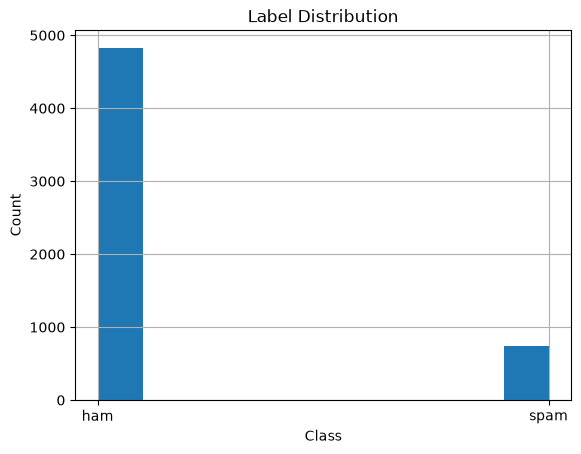

In [34]:
print("Dataset shape:", df.shape)
print("\nLabel distribution:")
print(df['label'].value_counts())
print("\nSpam percentage:", (df['label'] == 'spam').mean() * 100, "%")

# Visualize
df['label'].hist()
plt.title('Label Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

Dataset shape: (5572, 2)

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Spam percentage: 13.406317300789663 %


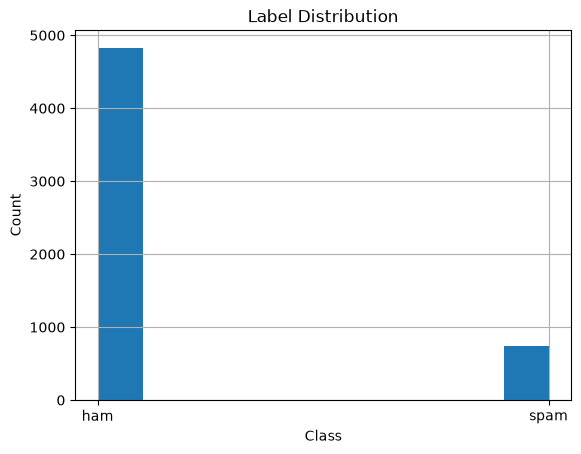

In [35]:
print("Dataset shape:", df.shape)
print("\nLabel distribution:")
print(df['label'].value_counts())
print("\nSpam percentage:", (df['label'] == 'spam').mean() * 100, "%")

# Visualize
df['label'].hist()
plt.title('Label Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [36]:
# Map: ham -> 0 (not spam), spam -> 1 (spam)
target_map = {'ham': 0, 'spam': 1}
df['target'] = df['label'].map(target_map)

df.head()

,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [37]:
df_train, df_test = train_test_split(df, random_state=42, test_size=0.2)

print("Train size:", len(df_train))
print("Test size:", len(df_test))

Train size: 4457
Test size: 1115


In [38]:
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english')

X_train = vectorizer.fit_transform(df_train['text']).toarray()
X_test = vectorizer.transform(df_test['text']).toarray()

Y_train = df_train['target'].values
Y_test = df_test['target'].values

print("X_train shape:", X_train.shape)
print("Y_train distribution:", np.bincount(Y_train))

X_train shape: (4457, 2000)
Y_train distribution: [3859  598]


In [39]:
D = X_train.shape[1]  # number of features (2000)

# Build model: Input -> Dense(1) with sigmoid in the loss
i = Input(shape=(D,))
x = Dense(1)(i)  # sigmoid is included in the loss function

model = Model(i, x)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 2000)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │           2,001 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,001 (7.82 KB)

 Trainable params: 2,001 (7.82 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(
    loss=BinaryCrossentropy(from_logits=True),
    optimizer=Adam(learning_rate=0.01),
    metrics=['accuracy']
)

r = model.fit(
    X_train, Y_train,
    validation_data=(X_test, Y_test),
    epochs=20,
    batch_size=128,
)

Epoch 1/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8658 - loss: 0.5650 - val_accuracy: 0.8664 - val_loss: 0.4506
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8723 - loss: 0.3785 - val_accuracy: 0.8861 - val_loss: 0.3244
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9002 - loss: 0.2812 - val_accuracy: 0.9139 - val_loss: 0.2549
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9246 - loss: 0.2243 - val_accuracy: 0.9318 - val_loss: 0.2115
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9376 - loss: 0.1869 - val_accuracy: 0.9417 - val_loss: 0.1817
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9513 - loss: 0.1604 - val_accuracy: 0.9507 - val_loss: 0.1599
Epoch 7/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9569 - loss: 0.1406 - val_accuracy: 0.9561 - val_loss: 0.1435
Epoch 8/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9628 - loss: 0.1253 - val_accuracy: 0.9596 - val_loss:

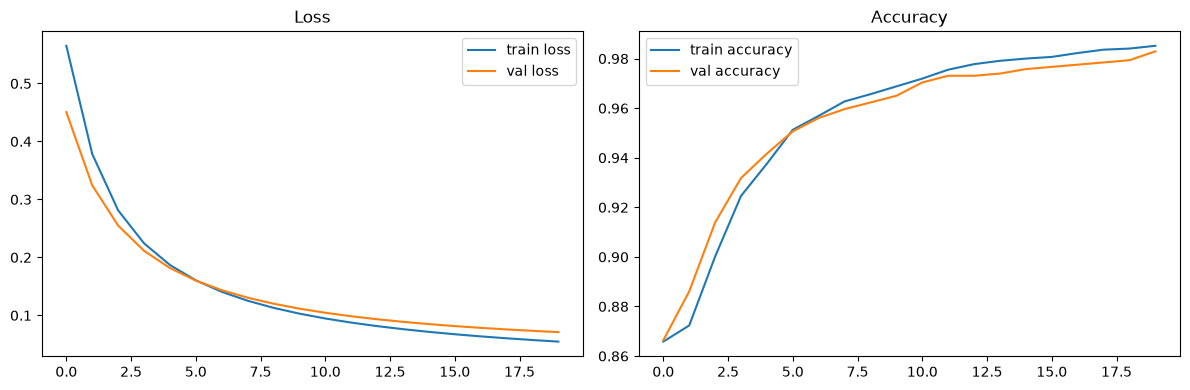

In [41]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend()
plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot(r.history['accuracy'], label='train accuracy')
plt.plot(r.history['val_accuracy'], label='val accuracy')
plt.legend()
plt.title('Accuracy')

plt.tight_layout()
plt.show()

In [42]:
# Get the weights of the Dense layer
W = model.layers[1].get_weights()[0]  # shape: (2000, 1)
word_index_map = vectorizer.vocabulary_

# Find words with HIGH positive weight → likely SPAM
print("=" * 50)
print("MOST SPAM-INDICATIVE WORDS (high positive weight)")
print("=" * 50)
threshold = 1.5

spam_words = []
for word, index in word_index_map.items():
    weight = W[index, 0]
    if weight > threshold:
        spam_words.append((word, weight))

spam_words.sort(key=lambda x: -x[1])  # sort descending
for word, weight in spam_words[:15]:
    print(f"{word:20s} {weight:.4f}")

print()
print("=" * 50)
print("MOST HAM-INDICATIVE WORDS (high negative weight)")
print("=" * 50)

ham_words = []
for word, index in word_index_map.items():
    weight = W[index, 0]
    if weight < -threshold:
        ham_words.append((word, weight))

ham_words.sort(key=lambda x: x[1])  # sort ascending (most negative first)
for word, weight in ham_words[:15]:
    print(f"{word:20s} {weight:.4f}")

MOST SPAM-INDICATIVE WORDS (high positive weight)
uk                   3.3759
www                  3.2880
txt                  3.1443
stop                 3.0633
dating               2.9865
150p                 2.9158
claim                2.8817
mobile               2.8556
50                   2.8452
freemsg              2.8430
service              2.8366
video                2.8281
reply                2.7869
18                   2.7757
won                  2.7590

MOST HAM-INDICATIVE WORDS (high negative weight)
ok                   -2.1852
ll                   -2.0399
gt                   -1.9962
lt                   -1.9884
way                  -1.9418
da                   -1.9377
sir                  -1.9352
later                -1.8928
home                 -1.8789
lol                  -1.8712
sorry                -1.8677
said                 -1.8673
mail                 -1.8561
doing                -1.8520
oh                   -1.8306


In [43]:
def predict_spam(text):
    # Transform the text using the SAME vectorizer
    X = vectorizer.transform([text]).toarray()
    prob = model.predict(X)[0, 0]
    
    # Apply sigmoid manually (since we used from_logits=True)
    from scipy.special import expit
    prob = expit(prob)
    
    label = "SPAM 🚨" if prob > 0.5 else "HAM ✅"
    print(f"Text: '{text}'")
    print(f"Spam probability: {prob:.4f}")
    print(f"Prediction: {label}\n")

# Test it!
predict_spam("Congratulations! You've won a $1000 Walmart gift card. Click here to claim!")
predict_spam("Hey mom, can you pick up milk on your way home? Love you!")
predict_spam("URGENT: Your account has been locked. Verify your identity now at bit.ly/xyz")
predict_spam("Are we still on for lunch tomorrow at noon?")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Text: 'Congratulations! You've won a $1000 Walmart gift card. Click here to claim!'
Spam probability: 0.6500
Prediction: SPAM 🚨

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Text: 'Hey mom, can you pick up milk on your way home? Love you!'
Spam probability: 0.0038
Prediction: HAM ✅

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Text: 'URGENT: Your account has been locked. Verify your identity now at bit.ly/xyz'
Spam probability: 0.2320
Prediction: HAM ✅

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Text: 'Are we still on for lunch tomorrow at noon?'
Spam probability: 0.0171
Prediction: HAM ✅



In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[]


![](https://deeplearningcourses.com/notebooks_v3_pxl?sc=rNqZPzHeg0A0iHxXRZdjOA&n=TF2+Classification)